# Сравнение алгоритмов
## Результаты лабораторных работ 1–5

Здесь я собираю результаты всех лабораторных, чтобы сравнить алгоритмы на одинаковых задачах.
Сейчас выполнены **№1 — KNN**, **№2 — логистическая и линейная регрессия**,
**№3 — решающее дерево**, **№4 — случайный лес**.
После работы №5 таблицы и графики будут дополнены.

| Задача | Данные | Основной показатель |
|:--|:--|:--|
| Одобрение кредитной заявки | Loan Approval | F1: больше — лучше |
| Прочность бетона | Concrete Strength | MAE, МПа: меньше — лучше |

Во всех работах использую одинаковые исходные данные и разбиения train/test.
Для бетона сохраняю разделение по рецептурам. Параметры выбираю по CV на train,
а здесь сравниваю итоговые результаты на test.

---

### Что именно сравнивается

Классификация — предварительное одобрение заявки (`loan_status`: 1 — одобрено, 0 — отказ)
по 12 признакам клиента и запроса, без процентной ставки.
Регрессия — прочность `strength` в МПа по восьми признакам состава и возраста бетона.
F1 учитывает precision и recall при дисбалансе классов; MAE — средняя абсолютная ошибка прочности.

### Условия эксперимента

| Параметр | Классификация | Регрессия |
|:--|:--|:--|
| Train / test | 36 000 / 9 000 заявок | 799 / 206 измерений |
| Разбиение | 80/20, со стратификацией | 80/20 по рецептурам, GroupShuffleSplit |
| Кросс-валидация | StratifiedKFold(3), shuffle=True | GroupKFold(3) по рецептурам |
| Случайное состояние | 42 | 42 |
| Выбор параметров | Максимум среднего F1 на train-CV | Минимум средней MAE на train-CV |

Рецептура — совпадение количеств всех семи компонентов смеси; возраст и прочность
не входят в ключ группы. Поэтому одна смесь в разных возрастах не пересекает train/test
и обучающие/валидационные части CV. Доля строк test для бетона составляет около 20,5%,
поскольку разделяются группы, а не отдельные измерения.

Все оценки CV считаю на полном train. Заполнение пропусков, кодирование и масштабирование
обучаются внутри каждого фолда. EDA использует только train. После выбора настроек
переобучаю модель на полном train и один раз оцениваю каждый зафиксированный вариант на test.
По результатам test параметры не меняю. Повторный поиск на одних CV-фолдах может завышать
оценку победившей конфигурации, поэтому отдельно показываю и CV, и test.


Для каждой работы сравниваю четыре варианта: исходный и улучшенный sklearn,
исходную и улучшенную свою модель. Внутри одной работы преобразования и параметры
библиотечной и своей моделей задаются одинаково; особенности реализации описаны отдельно. Между работами предобработка может различаться:
это часть исследуемого решения. Время включает преобразования, обучение или прогноз,
но не поиск параметров по CV; оно измерено одним запуском на текущей машине.


## 1. Результаты выполненных работ

Загружу сохранённые метрики. Отдельно покажу, какие лабораторные уже включены в сравнение.

In [1]:
# Ноутбук можно открыть из корня или каталога любой лабораторной.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Общий стиль таблиц и графиков.
MODEL_NAMES = {
    "sklearn_baseline": "sklearn · исходная",
    "sklearn_improved": "sklearn · улучшенная",
    "custom_baseline": "своя · исходная",
    "custom_improved": "своя · улучшенная",
    "dummy": "Dummy",
}
TASK_NAMES = {"classification": "Классификация", "regression": "Регрессия"}
COLUMN_NAMES = {
    "model": "Модель", "task": "Задача", "lab": "Работа", "dataset": "Набор данных",
    "algorithm": "Алгоритм", "implementation": "Реализация", "stage": "Вариант",
    "f1": "F1 ↑", "precision": "Precision", "recall": "Recall",
    "accuracy": "Accuracy", "balanced_accuracy": "Balanced accuracy",
    "roc_auc": "ROC-AUC", "average_precision": "AP", "mae": "MAE, МПа ↓",
    "rmse": "RMSE, МПа ↓", "r2": "R² ↑", "fit_seconds": "Обучение, с",
    "predict_seconds": "Прогноз, с", "mode": "Признаки", "representation": "Признаки",
    "cv_mean": "Среднее CV", "cv_std": "Разброс CV", "mean_test_score": "Среднее CV",
    "std_test_score": "Разброс CV", "rank_test_score": "Место", "status": "Статус",
    "comparison": "Сравнение", "delta": "Изменение", "metric": "Метрика",
    "estimator": "Алгоритм", "n_iter": "Итерации", "gradient_norm": "Норма градиента",
    "objective": "Функция потерь", "missing_train": "Пропуски", "dtype": "Тип",
    "missing": "Пропуски", "unique": "Уникальные", "type": "Тип",
    "param_model__n_neighbors": "Соседи (k)", "param_model__weights": "Веса",
    "param_model__p": "Расстояние (p)", "class_weight": "Веса классов",
    "count": "Количество", "fraction": "Доля", "train_fraction": "Доля в train",
}

def show_table(value, title=None):
    """Вывод таблицы с подписями и одинаковой точностью чисел."""
    if isinstance(value, pd.Series):
        value = value.to_frame()
    if not isinstance(value, pd.DataFrame):
        display(value)
        return
    table = value.copy()
    for column in table.columns:
        table[column] = table[column].map(
            lambda item: MODEL_NAMES.get(item, TASK_NAMES.get(item, item)) if isinstance(item, str) else item)
    table = table.rename(columns=COLUMN_NAMES)
    styled = table.style.format(precision=4, na_rep="—").set_table_styles([
        {"selector": "th", "props": [("background-color", "#edf3f8"), ("color", "#243b53"),
                                     ("padding", "9px 12px"), ("text-align", "left")]},
        {"selector": "td", "props": [("padding", "7px 12px"), ("border-bottom", "1px solid #e8edf2")]},
        {"selector": "caption", "props": [("caption-side", "top"), ("text-align", "left"),
                                          ("font-weight", "600"), ("padding", "10px 0")]},
    ])
    if isinstance(table.index, pd.RangeIndex):
        styled = styled.hide(axis="index")
    if title:
        styled = styled.set_caption(title)
    if "Норма градиента" in table.columns:
        styled = styled.format({"Норма градиента": "{:.2e}"})
    display(styled)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=["#387ca3", "#db9655", "#4c9c8a", "#9c7cb5"]),
})

ROOT =Path.cwd() if (Path.cwd() / "lab_1").is_dir() else Path.cwd().parent
required = {"lab", "algorithm", "model", "implementation", "stage", "task", "dataset", "target", "feature_set",
            "dataset_sha", "split_sha", "protocol_id", "n_train", "n_test", "fit_seconds", "predict_seconds"}
frames, status = [], []
for number in range(1, 6):
    file = ROOT / f"lab_{number}" / "results" / "metrics.csv"
    status.append({"lab": number, "status": "результаты доступны" if file.exists() else "результаты отсутствуют"})
    if file.exists():
        frame = pd.read_csv(file)
        if not required.issubset(frame.columns):
            raise ValueError(f"Неполная схема {file}: {required - set(frame.columns)}")
        if frame.empty or not frame.lab.eq(number).all():
            raise ValueError(f"Некорректные строки в {file}")
        frames.append(frame)
show_table(pd.DataFrame(status))
if not frames:
    raise RuntimeError("Файлы результатов отсутствуют")
results = pd.concat(frames, ignore_index=True)
assert not results.duplicated(["lab", "task", "model"]).any()
print(f"Получено {len(results)} строк; лабораторных: {results.lab.nunique()} из 5")

Работа,Статус
1,результаты доступны
2,результаты доступны
3,результаты доступны
4,результаты доступны
5,результаты отсутствуют


Получено 40 строк; лабораторных: 4 из 5


## 2. Сравнение качества

Сначала проверю, что совпадают данные, цель и разбиения.
Затем сравню исходные и улучшенные модели sklearn и свои реализации.
Dummy служит простым ориентиром, от которого стоит отталкиваться.

| Работа и задача | Исходный вариант | Улучшенный вариант |
|:--|:--|:--|
| №1 · классификация | KNN: k=5, p=2, uniform, без scaling | StandardScaler и log1p дохода; k=15, p=1, distance |
| №1 · регрессия | KNN: k=5, p=2, uniform, без scaling | StandardScaler, log1p возраста, признаки состава; k=5, p=2, distance |
| №2 · классификация | StandardScaler, LogisticRegression: C=1, обычные веса | Log-признаки, отношения, полиномы степени 2; C=0,1, обычные веса |
| №2 · регрессия | StandardScaler, LinearRegression без штрафа | Log-признаки, отношения, полиномы степени 2; Ridge alpha=1 |
| №3 · классификация | Gini, без ограничения глубины, лист от 1, обычные веса | Признаки, глубина, минимум в листе и веса выбраны по train-CV; настройки ниже |
| №3 · регрессия | squared_error, без ограничения глубины, лист от 1 | Признаки, глубина и минимум в листе выбраны по train-CV; настройки ниже |
| №4 · классификация | 100 деревьев, Gini, bootstrap, sqrt признаков, лист от 1 | Число деревьев, признаки, глубина, лист, max_features и веса выбраны по train-CV |
| №4 · регрессия | 100 деревьев, squared_error, bootstrap, все признаки, лист от 1 | Число деревьев, признаки, глубина, лист и max_features выбраны по групповой train-CV |

В №1 категории кодируются полным one-hot, в №2 — one-hot с удалением первого уровня.
Логистическая регрессия использует фиксированный порог 0,5.
Dummy всегда выбирает наиболее частый класс или медиану прочности.


В №3 использую полный one-hot без масштабирования в исходном варианте. Класс выбирается
по максимальной вероятности в листе, при равенстве — 0. Собственная CART использует
детерминированный порядок признаков; sklearn может иначе разрешать равенства выигрыша.

В №4 лес усредняет вероятности классов или прогнозы прочности отдельных деревьев.
Категории кодируются полным one-hot. Собственная реализация использует NumPy для CART,
bootstrap и выбора признаков в каждом узле. При материализации bootstrap повторные строки
входят в min_samples_* с кратностями; в sklearn эти ограничения считают уникальные строки.
OOB показан только как диагностика: для бетона он не исключает пересечение рецептур.


In [2]:
# Сначала проверяем протокол внутри каждой задачи, затем показываем результаты.
identity = ["dataset", "target", "feature_set", "dataset_sha", "split_sha", "protocol_id", "n_train", "n_test"]
for task, group in results.groupby("task"):
    if len(group[identity].drop_duplicates()) != 1:
        raise ValueError(f"Несопоставимые данные или разбиения для {task}")
    score = "f1" if task == "classification" else "mae"
    if score not in group or group[score].isna().any():
        raise ValueError(f"Отсутствуют метрики для {task}")
    columns = ["lab", "algorithm", "model"]
    columns += ["f1", "precision", "recall", "balanced_accuracy", "accuracy", "roc_auc", "average_precision"] if task == "classification" else ["mae", "rmse", "r2"]
    columns += ["fit_seconds", "predict_seconds"]
    print(TASK_NAMES[task])
    show_table(group[columns].sort_values(score, ascending=task != "classification").round(5))
# Точные настройки деревьев и лесов читаются из сохранённых протоколов.
import json
for number, name in [(3, "CART"), (4, "случайного леса")]:
    protocol_path = ROOT / f"lab_{number}" / "results" / "protocol.json"
    if protocol_path.exists():
        protocol = json.loads(protocol_path.read_text())
        settings = [{"task": task, "representation": config["mode"], **config["params"],
                     "CV-score (F1 / −MAE)": config["cv_score"]}
                    for task, config in protocol["selected"].items()]
        show_table(pd.DataFrame(settings), f"Выбранные настройки {name} (№{number})")


Классификация


,Работа,Алгоритм,Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP,"Обучение, с","Прогноз, с"
38,4,RandomForestClassifier,своя · улучшенная,0.7764,0.7657,0.7875,0.8593,0.8992,0.9596,0.8898,139.6668,1.1938
34,4,RandomForestClassifier,sklearn · улучшенная,0.7757,0.7412,0.8135,0.8662,0.8954,0.9591,0.8885,7.8687,0.0958
36,4,RandomForestClassifier,своя · исходная,0.7438,0.8453,0.6640,0.8146,0.8983,0.9543,0.8758,35.7201,0.9441
31,4,RandomForestClassifier,sklearn · исходная,0.7406,0.8478,0.6575,0.8119,0.8977,0.9546,0.8764,1.9706,0.0683
24,3,DecisionTreeClassifier,sklearn · улучшенная,0.7376,0.7839,0.6965,0.8208,0.8899,0.9388,0.8524,0.1152,0.0085
28,3,DecisionTreeClassifier,своя · улучшенная,0.7374,0.7827,0.6970,0.8209,0.8897,0.9385,0.8518,0.5574,0.0107
21,3,DecisionTreeClassifier,sklearn · исходная,0.7326,0.7263,0.7390,0.8297,0.8801,0.8297,0.5947,0.1230,0.0089
26,3,DecisionTreeClassifier,своя · исходная,0.7252,0.7157,0.7350,0.8258,0.8762,0.8258,0.5849,1.4727,0.0174
12,2,LogisticRegression,sklearn · улучшенная,0.7157,0.7702,0.6685,0.8057,0.8820,0.9403,0.8256,0.1778,0.0170
14,2,LogisticRegression,своя · улучшенная,0.7157,0.7702,0.6685,0.8057,0.8820,0.9403,0.8256,0.2191,0.0169


Регрессия


,Работа,Алгоритм,Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑,"Обучение, с","Прогноз, с"
39,4,RandomForestRegressor,своя · улучшенная,3.9479,5.7313,0.8982,20.8185,0.1761
35,4,RandomForestRegressor,sklearn · улучшенная,3.9766,5.7124,0.8989,0.4454,0.0132
7,1,KNN,sklearn · улучшенная,4.4187,6.7924,0.8570,0.0042,0.0027
9,1,KNN,своя · улучшенная,4.4218,6.7929,0.8570,0.0037,0.0076
25,3,DecisionTreeRegressor,sklearn · улучшенная,4.4701,7.0349,0.8466,0.0069,0.0023
37,4,RandomForestRegressor,своя · исходная,4.5787,6.6253,0.8640,7.4143,0.0826
33,4,RandomForestRegressor,sklearn · исходная,4.6535,6.6475,0.8630,0.1949,0.0073
29,3,DecisionTreeRegressor,своя · улучшенная,4.7931,7.5049,0.8254,0.1155,0.0035
19,2,LinearRegression,своя · улучшенная,4.8704,7.1397,0.8420,0.0063,0.0024
17,2,LinearRegression,sklearn · улучшенная,4.8704,7.1397,0.8420,0.0071,0.0024


Задача,Признаки,max_depth,min_samples_leaf,Веса классов,CV-score (F1 / −MAE)
Классификация,raw,—,20,—,0.7269
Регрессия,engineered,12.0000,1,—,-5.2542


Задача,Признаки,n_estimators,max_depth,min_samples_leaf,max_features,bootstrap,max_samples,oob_score,Веса классов,CV-score (F1 / −MAE)
Классификация,raw,200,—,5,0.7000,True,—,True,balanced_subsample,0.7614
Регрессия,engineered,200,—,1,1.0000,True,—,True,—,-3.9971


### Качество на графиках

Цвет показывает вариант модели. Для классификации лучше более длинный столбец F1,
для регрессии — более короткий столбец MAE. Числа возле столбцов позволяют
сравнить близкие результаты.

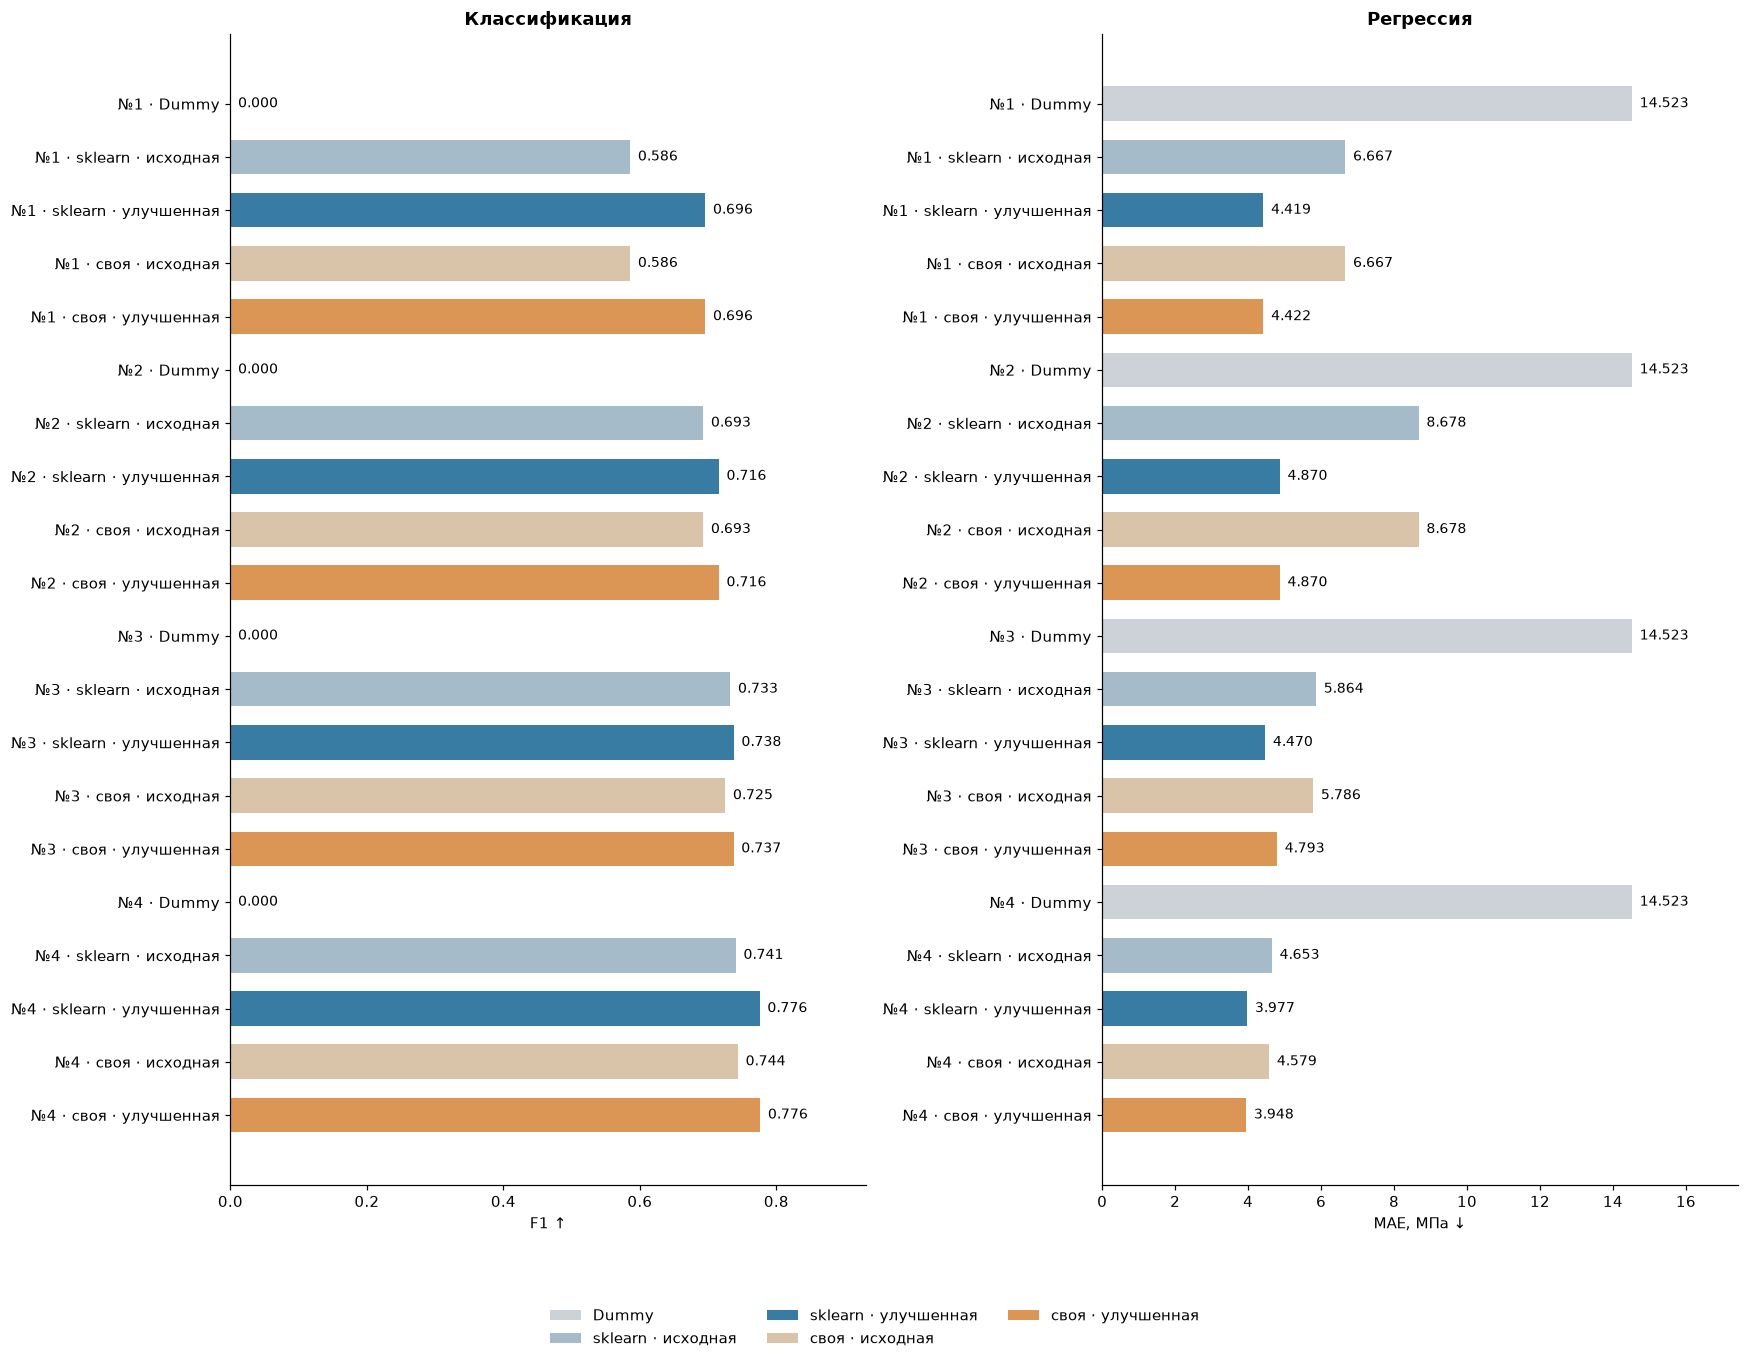

In [3]:
# Цвета вариантов одинаковы на обоих графиках.
from matplotlib.patches import Patch
colors = {"dummy": "#ccd2d7", "sklearn_baseline": "#a6bbc9", "sklearn_improved": "#387ca3",
          "custom_baseline": "#d9c4aa", "custom_improved": "#db9655"}
fig, axes = plt.subplots(1, 2, figsize=(16, max(7, results.lab.nunique() * 3)))
for ax, task, score in zip(axes, ["classification", "regression"], ["f1", "mae"]):
    group = results[results.task == task].copy()
    labels = [f"№{row.lab} · {MODEL_NAMES.get(row.model, row.model)}" for row in group.itertuples()]
    bars = ax.barh(labels, group[score], color=[colors.get(name, "#387ca3") for name in group.model], height=.65)
    ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=9)
    ax.set(title=TASK_NAMES[task], xlabel="F1 ↑" if score == "f1" else "MAE, МПа ↓")
    ax.set_xlim(0, group[score].max() * 1.20)
    ax.invert_yaxis()
fig.legend(handles=[Patch(facecolor=color, label=MODEL_NAMES[name]) for name, color in colors.items()],
           loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(.5, -.035))
plt.tight_layout(rect=(0, .05, 1, 1))
plt.show()

## 3. Что дали улучшения

Посмотрю на разницу между исходными и улучшенными моделями,
а также между своей реализацией и sklearn при одинаковых настройках.
Для F1 хорошо положительное изменение, для MAE — отрицательное.

In [4]:
# Разности показывают эффект улучшений и совпадение качества реализаций.
pairs = [("sklearn_improved", "sklearn_baseline", "Улучшение sklearn"),
         ("custom_baseline", "sklearn_baseline", "Своя и sklearn: исходные"),
         ("custom_improved", "sklearn_improved", "Своя и sklearn: улучшенные"),
         ("custom_improved", "custom_baseline", "Улучшение своей модели")]
deltas = []
for (lab, task), group in results.groupby(["lab", "task"]):
    metric = "f1" if task == "classification" else "mae"
    group = group.set_index("model")
    for left, right, label in pairs:
        if left in group.index and right in group.index:
            deltas.append({"lab": lab, "task": task, "Метрика": "F1" if metric == "f1" else "MAE, МПа",
                           "comparison": label, "delta": group.loc[left, metric] - group.loc[right, metric]})
show_table(pd.DataFrame(deltas))

Работа,Задача,Метрика,Сравнение,Изменение
1,Классификация,F1,Улучшение sklearn,0.1100
1,Классификация,F1,Своя и sklearn: исходные,0.0000
1,Классификация,F1,Своя и sklearn: улучшенные,0.0000
1,Классификация,F1,Улучшение своей модели,0.1100
1,Регрессия,"MAE, МПа",Улучшение sklearn,-2.2488
1,Регрессия,"MAE, МПа",Своя и sklearn: исходные,0.0000
1,Регрессия,"MAE, МПа",Своя и sklearn: улучшенные,0.0030
1,Регрессия,"MAE, МПа",Улучшение своей модели,-2.2457
2,Классификация,F1,Улучшение sklearn,0.0228
2,Классификация,F1,Своя и sklearn: исходные,0.0000


## 4. Итоги сравнения

Ниже собраны изменения основных метрик. Отдельно сравню улучшенные модели sklearn
между работами, чтобы увидеть, какой алгоритм лучше подошёл каждой задаче.

In [5]:
# В итоговую таблицу возьму улучшенные модели sklearn каждой работы.
final_rows = []
for lab, group in results[(results.implementation == "sklearn") & (results.stage == "improved")].groupby("lab"):
    classification = group[group.task == "classification"]
    regression = group[group.task == "regression"]
    if not classification.empty and not regression.empty:
        c, r = classification.iloc[0], regression.iloc[0]
        final_rows.append({"Работа": f"№{lab}", "Алгоритмы": "KNN" if lab == 1 else "Логистическая / линейная регрессия" if lab == 2 else str(c.algorithm),
                           "F1 ↑": c.f1, "MAE, МПа ↓": r.mae, "RMSE, МПа ↓": r.rmse, "R² ↑": r.r2})
show_table(pd.DataFrame(final_rows), "Итоговое сравнение на одинаковом test")

Работа,Алгоритмы,F1 ↑,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
№1,KNN,0.6960,4.4187,6.7924,0.8570
№2,Логистическая / линейная регрессия,0.7157,4.8704,7.1397,0.8420
№3,DecisionTreeClassifier,0.7376,4.4701,7.0349,0.8466
№4,RandomForestClassifier,0.7757,3.9766,5.7124,0.8989


### Выводы

Ниже выводы пересчитываются по сохранённым метрикам всех доступных лабораторных.
Сравниваются улучшенные модели sklearn на одинаковом test. Четыре варианта каждой
работы и разности их метрик приведены выше; результаты №5 пока отсутствуют.


In [6]:
# Выводы опираются на все доступные результаты и сохраняются в notebook.
for task, metric, title in [("classification", "f1", "F1"), ("regression", "mae", "MAE, МПа")]:
    group = results[(results.task == task) & (results.model == "sklearn_improved")]
    ranking = group.sort_values(metric, ascending=task == "regression")
    winner = ranking.iloc[0]
    details = "; ".join(f"№{int(row.lab)} · {row.algorithm}: **{getattr(row, metric):.5f}**"
                        for row in ranking.itertuples())
    display(Markdown(f"**{TASK_NAMES[task]} ({title}).** {details}. "
                     f"Лучший результат на этом test — **{winner.algorithm}, работа №{int(winner.lab)}**."))
    changes = []
    for lab, subset in results[results.task == task].groupby("lab"):
        m = subset.set_index("model")
        delta = m.loc["sklearn_improved", metric] - m.loc["sklearn_baseline", metric]
        own_delta = m.loc["custom_improved", metric] - m.loc["custom_baseline", metric]
        own_gap = m.loc["custom_improved", metric] - m.loc["sklearn_improved", metric]
        changes.append(f"№{lab}: улучшение sklearn **{delta:+.5f}**, своей модели **{own_delta:+.5f}**, "
                       f"своя минус sklearn после улучшений **{own_gap:+.5f}**")
    display(Markdown("Изменения " + title + " (лучше " + ("рост" if task == "classification" else "снижение") + "): "
                     + "; ".join(changes) + "."))


**Классификация (F1).** №4 · RandomForestClassifier: **0.77569**; №3 · DecisionTreeClassifier: **0.73762**; №2 · LogisticRegression: **0.71574**; №1 · KNN: **0.69597**. Лучший результат на этом test — **RandomForestClassifier, работа №4**.

Изменения F1 (лучше рост): №1: улучшение sklearn **+0.11004**, своей модели **+0.11004**, своя минус sklearn после улучшений **+0.00000**; №2: улучшение sklearn **+0.02280**, своей модели **+0.02280**, своя минус sklearn после улучшений **+0.00000**; №3: улучшение sklearn **+0.00503**, своей модели **+0.01216**, своя минус sklearn после улучшений **-0.00025**; №4: улучшение sklearn **+0.03505**, своей модели **+0.03267**, своя минус sklearn после улучшений **+0.00075**.

**Регрессия (MAE, МПа).** №4 · RandomForestRegressor: **3.97659**; №1 · KNN: **4.41873**; №3 · DecisionTreeRegressor: **4.47014**; №2 · LinearRegression: **4.87045**. Лучший результат на этом test — **RandomForestRegressor, работа №4**.

Изменения MAE, МПа (лучше снижение): №1: улучшение sklearn **-2.24876**, своей модели **-2.24574**, своя минус sklearn после улучшений **+0.00302**; №2: улучшение sklearn **-3.80764**, своей модели **-3.80764**, своя минус sklearn после улучшений **-0.00000**; №3: улучшение sklearn **-1.39401**, своей модели **-0.99271**, своя минус sklearn после улучшений **+0.32301**; №4: улучшение sklearn **-0.67688**, своей модели **-0.63081**, своя минус sklearn после улучшений **-0.02866**.

### Как интерпретировать сравнение

Между работами сравниваются полные решения с разной предобработкой. Лучшая модель
на одном test не обязательно окажется лучшей на новых данных. Метрики разных задач
не складываются в общую оценку; лучший алгоритм определяется отдельно для каждой задачи.

Свои KNN и линейные модели дают близкое к sklearn качество. Для деревьев одинаковые
критерии и параметры могут давать разные прогнозы из-за равноценных разбиений и
вычислений с плавающей точкой. В №3 фактическая доля расхождений, разности прогнозов,
глубина и число листьев показаны отдельно; совпадение математических свойств проверяется тестами.
Для лесов №4 дополнительно отличаются bootstrap, случайные наборы признаков и учёт повторных
строк в ограничениях узлов. Поэтому сравниваются качество и фактические расхождения,
а не побитовое совпадение ансамблей. В №4 отдельно показаны CV по трём seed,
важности и парные интервалы разностей; OOB не заменяет групповую CV.

При сравнении времени нужно учитывать устройство алгоритмов: KNN в основном запоминает train
и ищет соседей при прогнозе, линейные модели подбирают коэффициенты, а CART ищет пороги
при обучении и проходит по ветвям при прогнозе. Случайный лес строит много деревьев и усредняет их ответы. Время измерено одним запуском, включая
предобработку, без поиска параметров; это ориентир, а не устойчивый рейтинг скорости.

У всех работ одинаковые данные и разбиения. После просмотра нескольких алгоритмов один test
становится общим исследовательским ориентиром; окончательный выбор стоит проверить на новом
holdout или вложенной CV. Кредитный набор синтетический, а разделение бетона по рецептурам
не гарантирует полной независимости близких смесей.

**Источники данных:** [Loan Approval, taweilo, Kaggle](https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data)
и [Concrete Strength, Yeh (1998), UCI](https://doi.org/10.24432/C5PK67).

Работы **№1–4 выполнены**, **№5 ещё не выполнена**. Сводка автоматически включит результаты
следующих работ из `lab_N/results/metrics.csv`. Все таблицы, графики и численные выводы
сохранены в notebook и доступны без запуска кода.
